# Descriptive research analysis

This notebook reads `data/processed/abuse_flags_latest.csv` and reports descriptive feed counts and domain-age distributions.

Heuristic labels and registrant categories are candidates, not verified facts. URLhaus is community-sourced URL intelligence, not ground truth for registrar actions or compromise. OpenPhish has no per-URL event timestamp; `observed_at` records collection time. These summaries are not accuracy or false-positive rates without independently reviewed labels.


In [1]:
from __future__ import annotations

import csv
from collections import Counter, defaultdict
from pathlib import Path

# Locate the repository root by searching upward for data/processed.
def find_data_file(name: str) -> Path:
    start = Path.cwd().resolve()
    for base in (start, *start.parents):
        candidate = base / "data" / "processed" / name
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"{name} not found. Run `docker compose run --rm pipeline` first, then re-run this notebook."
    )

DATA_FILE = find_data_file("abuse_flags_latest.csv")


def parse_optional_int(value: str):
    value = (value or "").strip()
    if not value:
        return None
    try:
        return int(float(value))
    except ValueError:
        return None


with DATA_FILE.open(newline="", encoding="utf-8") as handle:
    rows = list(csv.DictReader(handle))

print(f"Loaded {len(rows)} rows from {DATA_FILE.name}")
print(f"Columns ({len(rows[0]) if rows else 0}):")
for col in (rows[0].keys() if rows else []):
    print(f"  - {col}")

preview_cols = ["flag_id", "source_feed", "classification_label", "domain_name", "registrant_category", "domain_age_at_flag_days"]
print("\nFirst 3 rows:")
for row in rows[:3]:
    print("  " + " | ".join(f"{c}={row.get(c, '')}" for c in preview_cols))


Loaded 26 rows from abuse_flags_latest.csv
Columns (32):
  - flag_id
  - source_feed
  - source_record_id
  - raw_snapshot
  - source_url
  - timestamp_basis
  - threat_type
  - flagged_url
  - flagged_at
  - observed_at
  - classification_label
  - domain_age_at_flag_days
  - heuristic_confidence_score
  - classification_rule_version
  - triage_features
  - domain_name
  - tld
  - registrar_name
  - registrant_category
  - rdap_source_url
  - rdap_observed_at
  - rdap_epp_statuses
  - epp_status_applied
  - observed_epp_statuses
  - recommended_action
  - human_review_status
  - prior_notice_sent
  - cure_period_hours
  - collateral_impact_score
  - due_process_compliant
  - research_note
  - case_notes

First 3 rows:
  flag_id=1 | source_feed=OpenPhish | classification_label=Unverified | domain_name=backname.io | registrant_category=Unknown | domain_age_at_flag_days=
  flag_id=2 | source_feed=OpenPhish | classification_label=Unverified | domain_name=webflow.io | registrant_category=U

In [2]:
feed_counts = Counter(r["source_feed"] for r in rows)
unique_urls = len({r["flagged_url"] for r in rows})
print(f"Unique flagged URLs: {unique_urls:,} across {len(feed_counts)} feed(s)")
for feed, count in feed_counts.most_common():
    print(f"  {feed}: {count} rows")

print("\nRows by source_feed x classification_label:")
groups = defaultdict(Counter)
for r in rows:
    groups[r["source_feed"]][r["classification_label"]] += 1
for feed in sorted(groups):
    print(f"  {feed}:")
    for label, count in sorted(groups[feed].items()):
        print(f"    {label}: {count}")


Unique flagged URLs: 26 across 2 feed(s)
  OpenPhish: 25 rows
  URLhaus: 1 rows

Rows by source_feed x classification_label:
  OpenPhish:
    Possible_Maliciously_Registered: 9
    Unverified: 16
  URLhaus:
    Unverified: 1


In [3]:
ages = [parse_optional_int(r["domain_age_at_flag_days"]) for r in rows]
ages = [a for a in ages if a is not None]
print(f"Rows with RDAP-derived domain age: {len(ages)} of {len(rows)}")

if not ages:
    print("No RDAP-derived domain ages are available in this export "
          "(RDAP lookups returned no creation date for most domains).")
else:
    ages_sorted = sorted(ages)
    n = len(ages_sorted)
    def quantile(p):
        return ages_sorted[min(n - 1, int(round(p * (n - 1))))]
    print(f"  count={n}, min={ages_sorted[0]}, median={quantile(0.5)}, max={ages_sorted[-1]}")
    print(f"  quartiles: Q1={quantile(0.25)}, Q3={quantile(0.75)}")

    # ASCII histogram (no third-party dependencies). Install matplotlib for a
    # publication-quality plot if desired.
    bins = 20
    width = 50
    lo, hi = ages_sorted[0], ages_sorted[-1]
    step = (hi - lo) / bins if hi > lo else 1
    counts = [0] * bins
    for v in ages:
        idx = min(bins - 1, int((v - lo) / step))
        counts[idx] += 1
    max_count = max(counts)
    print("\n  Distribution (ASCII histogram):")
    for i, c in enumerate(counts):
        lo_b = lo + i * step
        hi_b = lo + (i + 1) * step
        bar = "#" * max(1, round(c / max_count * width))
        print(f"  {lo_b:>8.0f}-{hi_b:<8.0f} | {bar} ({c})")


Rows with RDAP-derived domain age: 0 of 26
No RDAP-derived domain ages are available in this export (RDAP lookups returned no creation date for most domains).


In [4]:
print("Summary by classification_label x registrant_category:")
summary = defaultdict(lambda: {"rows": 0, "ages": [], "reviewed": 0})
for r in rows:
    key = (r["classification_label"], r["registrant_category"])
    summary[key]["rows"] += 1
    a = parse_optional_int(r["domain_age_at_flag_days"])
    if a is not None:
        summary[key]["ages"].append(a)
    if (r.get("human_review_status") or "not_reviewed") != "not_reviewed":
        summary[key]["reviewed"] += 1

print(f"{'classification_label':<34} {'registrant_category':<28} {'rows':>5} {'mean_age':>9} {'reviewed':>9}")
print("-" * 92)
for (label, cat), s in sorted(summary.items(), key=lambda kv: -kv[1]["rows"]):
    mean_age = f"{sum(s['ages'])/len(s['ages']):.1f}" if s["ages"] else "-"
    print(f"{label:<34} {cat:<28} {s['rows']:>5} {mean_age:>9} {s['reviewed']:>9}")


Summary by classification_label x registrant_category:
classification_label               registrant_category           rows  mean_age  reviewed
--------------------------------------------------------------------------------------------
Unverified                         Unknown                         16         -         0
Possible_Maliciously_Registered    Unknown                          9         -         0
Unverified                         NonCommercial_Candidate          1         -         0


## Publication plots

The plots below require **matplotlib** (not available in every kernel). If it is missing, the cell prints a hint and a pre-rendered PNG is committed at `data/processed/figures/classification_overview.png`. The companion script `notebooks/make_figures.py` produces the same figure with only Pillow.


domain_type: {'registered': 9, 'platform': 17}
RDAP metadata: 5/26 | creation date: 0/26 | reviewed: 0/26
Saved C:\Users\soyam\Documents\GitHub\dns-abuse-proportionality\data\processed\figures\classification_overview.png


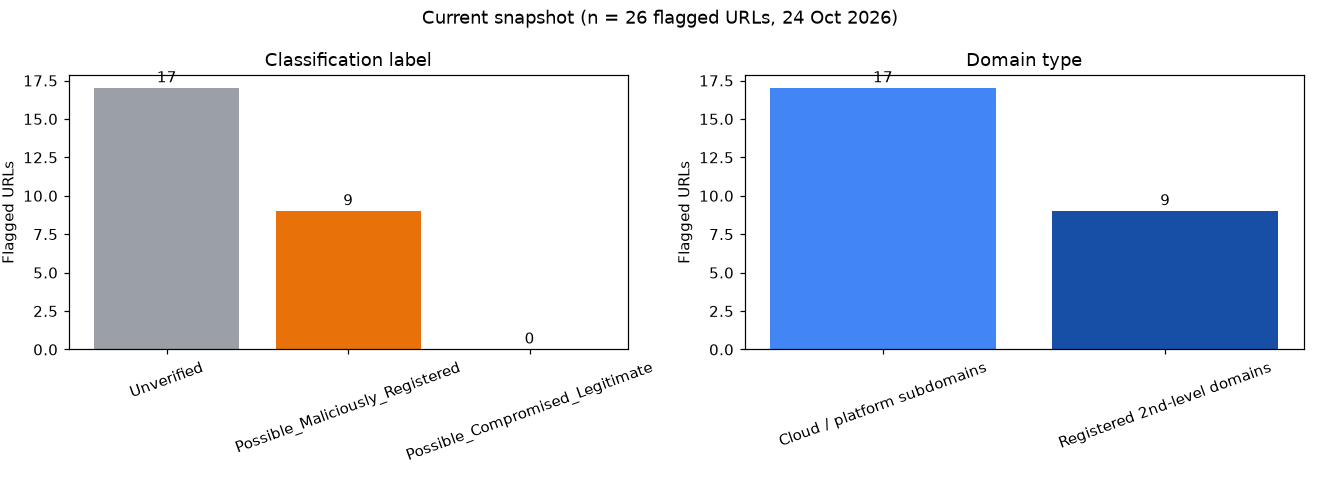

In [5]:
from collections import Counter

PLATFORM_SUFFIXES = (
    "vercel.app", "pages.dev", "blogspot.com", "webflow.io",
    "cloudfront.net", "githubusercontent.com", "netlify.app",
    "herokuapp.com", "appspot.com",
)

def domain_type(domain: str) -> str:
    d = (domain or "").strip().lower()
    if any(d == s or d.endswith("." + s) for s in PLATFORM_SUFFIXES):
        return "platform"
    return "registered"

labels = Counter(r["classification_label"] for r in rows)
dtypes = Counter(domain_type(r["domain_name"]) for r in rows)
rdap_meta = sum(1 for r in rows if (r.get("rdap_observed_at") or "").strip())
rdap_age = sum(1 for r in rows if (r.get("domain_age_at_flag_days") or "").strip())
reviewed = sum(1 for r in rows if (r.get("human_review_status") or "not_reviewed") != "not_reviewed")

print(f"domain_type: {dict(dtypes)}")
print(f"RDAP metadata: {rdap_meta}/{len(rows)} | creation date: {rdap_age}/{len(rows)} | reviewed: {reviewed}/{len(rows)}")

try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
except ImportError:
    print("\nmatplotlib is not installed in this kernel. Install it (Python <= 3.13) "
          "or run in the Docker image; the pre-rendered PNG is at "
          "data/processed/figures/classification_overview.png.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

    order = ["Unverified", "Possible_Maliciously_Registered", "Possible_Compromised_Legitimate"]
    vals = [labels.get(k, 0) for k in order]
    colors = ["#9aa0a6", "#e8710a", "#188038"]
    bars = axes[0].bar(order, vals, color=colors)
    axes[0].set_title("Classification label")
    axes[0].set_ylabel("Flagged URLs")
    axes[0].tick_params(axis="x", rotation=20)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width() / 2, v + 0.15, str(v), ha="center", va="bottom")

    dorder = ["Cloud / platform subdomains", "Registered 2nd-level domains"]
    dvals = [dtypes.get("platform", 0), dtypes.get("registered", 0)]
    dcolors = ["#4285f4", "#174ea6"]
    bars2 = axes[1].bar(dorder, dvals, color=dcolors)
    axes[1].set_title("Domain type")
    axes[1].set_ylabel("Flagged URLs")
    axes[1].tick_params(axis="x", rotation=20)
    for b, v in zip(bars2, dvals):
        axes[1].text(b.get_x() + b.get_width() / 2, v + 0.15, str(v), ha="center", va="bottom")

    fig.suptitle(f"Current snapshot (n = {len(rows)} flagged URLs, 24 Oct 2026)")
    fig.tight_layout()

    out_dir = DATA_FILE.parent / "figures"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / "classification_overview.png"
    fig.savefig(out_path, dpi=150)
    print("Saved", out_path)
    plt.show()
